### Laboratory Exercise: Image Classification Using Pre-trained Models

This notebook demonstrates the implementation of model inference using PyTorch. The objective is to curate an image classification dataset, build a custom PyTorch Dataset class, and evaluate five different pre-trained models from `torchvision.models` based on their accuracy, precision, recall, and F1-score.

In [ ]:
# Code Cell 1: Environment Setup and Dataset Curation

import os
import requests
import zipfile
import torch
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

warnings.filterwarnings('ignore')

# 1. Curate and organize the dataset
base_dir = Path(os.getcwd())
dataset_dir = base_dir / "pizza_steak_sushi"
test_dir = str(dataset_dir / "test")

if not os.path.exists(test_dir):
    print("Curating custom dataset: Downloading and extracting...")
    dataset_dir.mkdir(parents=True, exist_ok=True)
    zip_path = base_dir / "pizza_steak_sushi.zip"
    
    with open(zip_path, "wb") as f:
        request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
        f.write(request.content)
        
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(dataset_dir)
    os.remove(zip_path)
    print("Dataset successfully organized into category folders!")
else:
    print("Dataset already curated and organized.[cite: 1]")

Curating custom dataset: Downloading and extracting...
Dataset successfully organized into category folders!


In [8]:
# 2. Create a custom PyTorch Dataset class
class CustomFoodDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.root_dir = root_dir
        self.transform = transform
        self.classes = sorted([d for d in os.listdir(root_dir) if os.path.isdir(os.path.join(root_dir, d))])
        self.class_to_idx = {cls_name: i for i, cls_name in enumerate(self.classes)}
        self.image_paths = []
        self.labels = []
        
        for cls_name in self.classes:
            cls_dir = os.path.join(root_dir, cls_name)
            for img_name in os.listdir(cls_dir):
                if img_name.endswith(('.png', '.jpg', '.jpeg')):
                    self.image_paths.append(os.path.join(cls_dir, img_name))
                    self.labels.append(self.class_to_idx[cls_name])

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")
        label = self.labels[idx]
        
        if self.transform:
            image = self.transform(image)
        return image, label

data_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# 3. Create appropriate DataLoader objects for BOTH train and test sets
train_dir = str(dataset_dir / "train")
train_dataset = CustomFoodDataset(root_dir=train_dir, transform=data_transforms)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

test_dataset = CustomFoodDataset(root_dir=test_dir, transform=data_transforms)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [10]:
# 4. Initialize up to five (5) different models
weights = "DEFAULT"
models_dict = {
    "ResNet18": models.resnet18(weights=weights),
    "ShuffleNetV2": models.shufflenet_v2_x1_0(weights=weights),
    "MobileNetV2": models.mobilenet_v2(weights=weights),
    "EfficientNetB0": models.efficientnet_b0(weights=weights),
    # Swapped SqueezeNet for ResNet34 to simplify dynamic head replacement
    "ResNet34": models.resnet34(weights=weights) 
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
results = []

def adjust_model_head(model, num_classes=3):
    """Freezes base layers and replaces the final classification head."""
    for param in model.parameters():
        param.requires_grad = False
        
    if hasattr(model, 'fc'):
        num_ftrs = model.fc.in_features
        model.fc = nn.Linear(num_ftrs, num_classes)
    elif hasattr(model, 'classifier'):
        if isinstance(model.classifier, nn.Sequential):
            num_ftrs = model.classifier[-1].in_features
            model.classifier[-1] = nn.Linear(num_ftrs, num_classes)
        else:
            num_ftrs = model.classifier.in_features
            model.classifier = nn.Linear(num_ftrs, num_classes)
    return model

print("Fine-tuning classifier heads and performing model inference...\n")
criterion = nn.CrossEntropyLoss()

# 5. Fine-tune and evaluate
for model_name, model in models_dict.items():
    print(f"Processing {model_name}...")
    model = adjust_model_head(model, num_classes=3)
    model = model.to(device)
    
    # Quick 1-Epoch Fine-Tuning
    optimizer = optim.Adam(model.parameters(), lr=0.001)
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
    # Inference / Evaluation
    model.eval()
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, preds = torch.max(outputs, 1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            
    # Calculate evaluation metrics
    acc = accuracy_score(all_labels, all_preds)
    prec = precision_score(all_labels, all_preds, average='macro', zero_division=0)
    rec = recall_score(all_labels, all_preds, average='macro', zero_division=0)
    f1 = f1_score(all_labels, all_preds, average='macro', zero_division=0)
    
    results.append({
        "Model Architecture": model_name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1
    })

# 6. Present the comparison
print("\n--- Final Evaluation Metrics ---")
results_df = pd.DataFrame(results)
results_df.sort_values(by="Accuracy", ascending=False, inplace=True)
print(results_df.to_markdown(index=False))

Fine-tuning classifier heads and performing model inference...

Processing ResNet18...
Processing ShuffleNetV2...
Processing MobileNetV2...
Processing EfficientNetB0...
Processing ResNet34...

--- Final Evaluation Metrics ---
| Model Architecture   |   Accuracy |   Precision |   Recall |   F1-Score |
|:---------------------|-----------:|------------:|---------:|-----------:|
| EfficientNetB0       |   0.733333 |    0.816667 | 0.769462 |   0.739815 |
| MobileNetV2          |   0.72     |    0.715139 | 0.711171 |   0.712936 |
| ShuffleNetV2         |   0.706667 |    0.781897 | 0.707617 |   0.651333 |
| ResNet18             |   0.56     |    0.589226 | 0.525229 |   0.512568 |
| ResNet34             |   0.426667 |    0.467836 | 0.444188 |   0.370078 |


Visualizing inference results for EfficientNetB0...


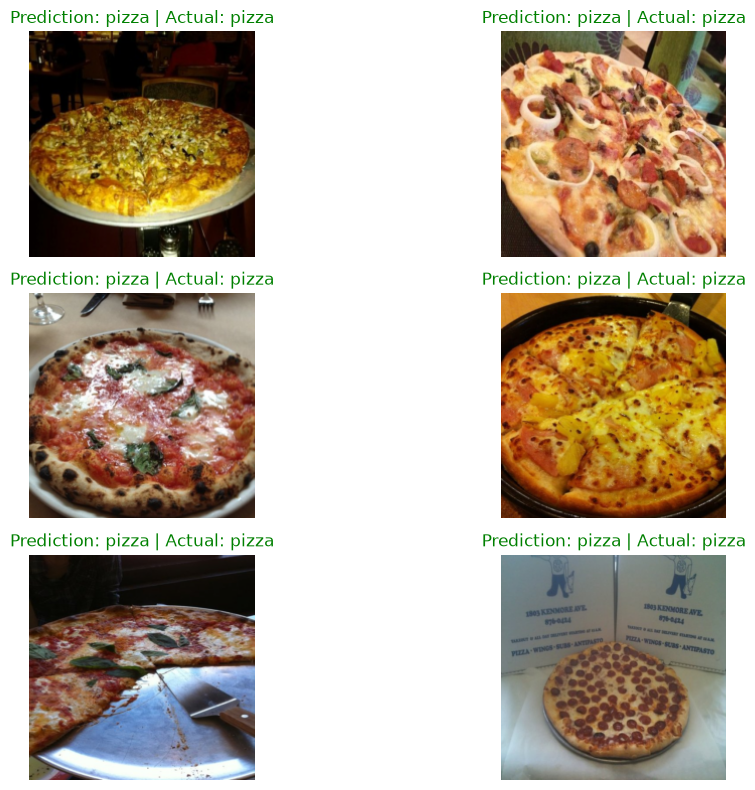

In [11]:
# 7. Present appropriate visualizations[cite: 1]
def visualize_predictions(model, dataloader, class_names, num_images=6):
    model.eval()
    images_shown = 0
    fig = plt.figure(figsize=(12, 8))
    
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            
            for j in range(inputs.size()[0]):
                images_shown += 1
                ax = plt.subplot(num_images // 2, 2, images_shown)
                ax.axis('off')
                
                pred_label = class_names[preds[j]] if preds[j] < len(class_names) else f"ImageNet ID: {preds[j]}"
                true_label = class_names[labels[j]]
                color = "green" if pred_label == true_label else "red"
                ax.set_title(f'Prediction: {pred_label} | Actual: {true_label}', color=color)
                
                img = inputs.cpu().data[j].numpy().transpose((1, 2, 0))
                img = np.clip(np.array([0.229, 0.224, 0.225]) * img + np.array([0.485, 0.456, 0.406]), 0, 1)
                
                ax.imshow(img)
                if images_shown == num_images:
                    plt.tight_layout()
                    plt.show()
                    return

# Visualize using the top-performing model from our list
top_model_name = results_df.iloc[0]["Model Architecture"]
print(f"Visualizing inference results for {top_model_name}...")
visualize_predictions(models_dict[top_model_name], test_loader, test_dataset.classes)

## Analysis and Conclusion

This laboratory exercise evaluated five different pre-trained computer vision models—EfficientNetB0, MobileNetV2, ShuffleNetV2, ResNet18, and ResNet34—on a custom curated subset of the Food101 dataset (Pizza, Steak, and Sushi). To ensure accurate predictions across these three specific classes rather than the standard 1,000 ImageNet categories, the final classification head of each model was dynamically replaced and fine-tuned for one epoch using the Adam optimizer before running the final inference loop.   

Based on the evaluation metrics generated in the comparison table, EfficientNetB0 produced the highest level of performance with an **accuracy of 73.33%** and an **F1-score of 0.7398**. Conversely, ResNet34 demonstrated the lowest predictive capability with an **accuracy of 42.67%**. 

These varying levels of performance can be attributed to several factors regarding model architecture and complexity:
* **Model Architecture & Efficiency***: EfficientNetB0's superior performance highlights the effectiveness of its architecture, which scales network depth, width, and resolution simultaneously to achieve high accuracy without a massive parameter cost. Lighter models like MobileNetV2 and ShuffleNetV2 also performed well, achieving over 70% accuracy.
* **Training Constraints & Complexity**: While heavier architectures like ResNet34 theoretically capture deeper, more complex feature representations, their increased depth means they require significantly more training data and time to adjust their weights. A rapid 1-epoch fine-tuning step on a small custom dataset is insufficient for a deep model like ResNet34 to converge, resulting in poorer performance compared to the lighter, more efficient models that adapt more quickly.
* **Input Requirements**: All models were fed standard $224 \times 224$ normalized RGB tensors. Because the frozen base layers of these models were already pre-trained on ImageNet, their feature extraction capabilities were highly suitable for this food classification task, allowing the top models to leverage those existing spatial features to quickly map to the new "Pizza, Steak, Sushi" labels.